# **PROBLEM STATEMENT**:

The hospitality industry has undergone a significant transformation with the rise of online platforms facilitating short-term lodging and tourism.
Leading this revolution is Airbnb, Inc., a pioneering American company that has reshaped travel accommodation through its innovative online
marketplace. Established in 2008 in San Francisco, California, Airbnb provides a diverse range of lodging options, offering guests a unique and
personalized experience. Unlike traditional hospitality providers, Airbnb operates on a commission-based model, facilitating transactions
between hosts and guests without owning the properties listed on its platform.
This research analysis delves into the New York City Airbnb dataset to extract meaningful insights. Through rigorous data cleaning, exploratory
analysis, and visualization techniques, the study aims to illuminate the dynamics of the city's lodging market. By discerning factors influencing
listing availability, pricing strategies, and overall customer satisfaction, the research contributes to a deeper understanding of Airbnb's
operations in one of the world's most dynamic urban environments. These insights hold significance for stakeholders and enthusiasts seeking
to navigate the evolving landscape of short-term accommodation.

# **QUESTIONS**:
This project is aimed to uncover some insights from the Airbnb Open Data. The following questions would be answered from the data.
1. What are the different property types in the Dataset?
2. Which neighborhood group has the highest number of listings?
3. Which neighborhoods group have the highest average prices for Airbnb listings?
4. Is there a relationship between the construction year of property and price?
5. Who are the top 10 hosts by calculated host listing count?
6. Are hosts with verified identities more likely to receive positive reviews?
7. Is there a correlation between the price of a listing and its service fee?
8. What is the average review rate number (e.g., stars) for listings, and does it vary based on the neighborhood group and room type?
9. Are hosts with a higher calculated host listings count more likely to maintain higher availability throughout the year?

# **DATA WRANGLING**:

Data wrangling, a crucial phase in the data analysis process, involves preparing and cleaning raw data to make it suitable for analysis. This
involves various tasks such as handling missing values, removing duplicates, and transforming data into a consistent format. Effective data
wrangling ensures that the data is reliable and ready for exploration, enabling meaningful insights to be derived from it.

In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Show every column in displayed DataFrames (display setting only)
pd.set_option("display.max_columns", None)

# ---------------------------------------------------------------
# Official Airbnb palette + reusable plotting theme (styling only)
# ---------------------------------------------------------------
AIRBNB_CORAL = "#FF5A5F"   # primary brand colour
AIRBNB_TEAL = "#00A699"    # secondary series / positive highlights
AIRBNB_ORANGE = "#FC642D"  # third series / selected highlights
AIRBNB_DARK = "#484848"    # titles, labels, primary text
AIRBNB_GRAY = "#767676"    # secondary text, gridlines, annotations

AIRBNB_COLORS = [AIRBNB_CORAL, AIRBNB_TEAL, AIRBNB_ORANGE, AIRBNB_DARK, AIRBNB_GRAY]

# Fixed category-to-colour mappings (identical on the StayScope website)
ROOM_TYPE_COLORS = {
    "Entire home/apt": AIRBNB_CORAL,
    "Private room": AIRBNB_TEAL,
    "Shared room": AIRBNB_ORANGE,
    "Hotel room": AIRBNB_DARK,
}
NEIGHBOURHOOD_COLORS = {
    "Manhattan": AIRBNB_CORAL,
    "Brooklyn": AIRBNB_TEAL,
    "Queens": AIRBNB_ORANGE,
    "Bronx": AIRBNB_DARK,
    "Staten Island": AIRBNB_GRAY,
}
VERIFICATION_COLORS = {"verified": AIRBNB_TEAL, "unconfirmed": AIRBNB_CORAL}

sns.set_theme(style="whitegrid", palette=AIRBNB_COLORS)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": AIRBNB_GRAY,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlecolor": AIRBNB_DARK,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.labelcolor": AIRBNB_DARK,
    "axes.labelsize": 11,
    "text.color": AIRBNB_DARK,
    "xtick.color": AIRBNB_GRAY,
    "ytick.color": AIRBNB_GRAY,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "grid.color": AIRBNB_GRAY,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
    "legend.frameon": False,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
})

In [106]:
from pathlib import Path

possible_paths = [
    Path("1776250134-P4-Airbnb Hotel Booking Analysis.xlsx"),
    Path("/content/1776250134-P4-Airbnb Hotel Booking Analysis.xlsx"),
    Path("/mnt/data/1776250134-P4-Airbnb Hotel Booking Analysis.xlsx"),
]
excel_path = next((p for p in possible_paths if p.exists()), None)

if excel_path is None:
    raise FileNotFoundError(
        "Place '1776250134-P4-Airbnb Hotel Booking Analysis.xlsx' in the same "
        "folder as this notebook (or upload it to /content in Google Colab)."
    )

raw_df = pd.read_excel(excel_path)
df = raw_df.copy()
print(f"Loaded: {excel_path}")
print(f"Original shape: {df.shape}")


Loaded: 1776250134-P4-Airbnb Hotel Booking Analysis.xlsx
Original shape: (102599, 26)


# **ACCESS THE DATA**:



In [107]:
df.head()

,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,country code,instant_bookable,cancellation_policy,room type,Construction year,price,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,US,0.0,strict,Private room,2020.0,966.0,193.0,10.0,9.0,2021-10-19,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,US,0.0,moderate,Entire home/apt,2007.0,142.0,28.0,30.0,45.0,2022-05-21,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,US,1.0,flexible,Private room,2005.0,620.0,124.0,3.0,0.0,NaT,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,US,1.0,moderate,Entire home/apt,2005.0,368.0,74.0,30.0,270.0,2019-07-05,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,US,0.0,moderate,Entire home/apt,2009.0,204.0,41.0,10.0,9.0,2018-11-19,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN


In [108]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102599 entries, 0 to 102598
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   id                              102599 non-null  int64         
 1   NAME                            102329 non-null  object        
 2   host id                         102599 non-null  int64         
 3   host_identity_verified          102310 non-null  object        
 4   host name                       102191 non-null  object        
 5   neighbourhood group             102570 non-null  object        
 6   neighbourhood                   102583 non-null  object        
 7   lat                             102591 non-null  float64       
 8   long                            102591 non-null  float64       
 9   country                         102067 non-null  object        
 10  country code                    102468 non-null  object 

In [109]:
df.duplicated().value_counts()

False    102058
True        541
Name: count, dtype: int64

In [110]:
# Neighbourhood group was 'brookln' instead of 'Brooklyn'
df[df['neighbourhood group'] == 'brookln']

,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,country code,instant_bookable,cancellation_policy,room type,Construction year,price,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
13,1008516,"Lovely Room 1, Garden, Best Area, Legal rental",26802410424,verified,Darcy,brookln,South Slope,40.66829,-73.98779,United States,US,1.0,moderate,Private room,2010.0,580.0,116.0,4.0,167.0,2019-06-24,1.34,4.0,3.0,47.0,NaN,NaN


# **Problems Identified within the Data**

The initial inspection identified the following data-quality issues:

- 541 duplicate records.
- `house_rules` and `license` contain substantial missing information and are not used in the nine research questions.
- Missing values occur in several columns, particularly `last review` and `reviews per month`.
- Some columns require explicit type conversion, including identifiers, price, service fee, and construction year.
- The values `brookln` and `manhatan` are spelling inconsistencies in `neighbourhood group`.
- `availability 365` contains values outside its valid range of 0–365, including negative values.
- `minimum nights` contains non-positive and unusually large values.

**Important:** The source Excel file stores `price` and `service fee` as numeric values; dollar signs and commas are not present in the uploaded file. The cleaning code still uses numeric coercion so it remains robust if formatted strings appear in another copy.


# **CLEAN THE DATA:**

# **Steps to be Taken for Data Cleaning**

- Remove duplicate records.
- Drop `house_rules` and `license` because they are not used in this analysis and contain extensive missing information.
- Convert `price` and `service fee` to numeric values safely.
- Rename the columns to `price_$` and `service_fee_$`.
- Convert identifiers to string types, parse `last review` as a date, and convert `Construction year` to a nullable integer.
- Standardize `brookln` as `Brooklyn` and `manhatan` as `Manhattan`.
- Preserve rows with missing values in fields not needed for a particular question. Each analysis will exclude missing values only from the columns it uses.
- For the availability analysis, use only values in the valid range of 0–365. Do not remove otherwise useful listings from the entire dataset just because availability is invalid.
- Flag invalid `minimum nights` values rather than silently deleting otherwise useful records.


In [111]:
# 1. Remove duplicate records
df = df.drop_duplicates().copy()

# 2. Drop columns not used in this analysis and containing extensive missing data
df = df.drop(columns=["house_rules", "license"], errors="ignore")

# 3. Convert price and service fee safely to numeric values.
# This handles both numeric Excel cells and strings such as "$1,200".
for col in ["price", "service fee"]:
    cleaned = (
        df[col].astype("string")
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )
    df[col] = pd.to_numeric(cleaned, errors="coerce")

# 4. Rename price-related columns
df = df.rename(columns={
    "price": "price_$",
    "service fee": "service_fee_$"
})

# 5. Convert identifiers and date/year fields
df["id"] = df["id"].astype("string")
df["host id"] = df["host id"].astype("string")
df["last review"] = pd.to_datetime(df["last review"], errors="coerce")
df["Construction year"] = pd.to_numeric(
    df["Construction year"], errors="coerce"
).astype("Int64")

# Ensure analysis fields are numeric
numeric_cols = [
    "minimum nights", "number of reviews", "reviews per month",
    "review rate number", "calculated host listings count",
    "availability 365"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 6. Standardize neighbourhood-group spelling and whitespace
df["neighbourhood group"] = (
    df["neighbourhood group"].astype("string").str.strip()
)
neighbourhood_corrections = {
    "brookln": "Brooklyn",
    "manhatan": "Manhattan"
}
df["neighbourhood group"] = df["neighbourhood group"].replace(
    neighbourhood_corrections
)

print("Cleaning completed.")
print("Shape after duplicate and unused-column removal:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())
print("Missing values are retained where they are not required for a specific analysis.")
print("Availability values outside 0-365:", int((~df["availability 365"].between(0, 365)).sum()))
print("Minimum nights <= 0:", int((df["minimum nights"] <= 0).sum()))
print("Minimum nights > 365:", int((df["minimum nights"] > 365).sum()))


Cleaning completed.
Shape after duplicate and unused-column removal: (102058, 24)
Duplicate rows remaining: 0
Missing values are retained where they are not required for a specific analysis.
Availability values outside 0-365: 3633
Minimum nights <= 0: 13
Minimum nights > 365: 35


In [112]:
df.duplicated().value_counts()

False    102058
Name: count, dtype: int64

In [113]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 102058 entries, 0 to 102057
Data columns (total 24 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   id                              102058 non-null  string        
 1   NAME                            101788 non-null  object        
 2   host id                         102058 non-null  string        
 3   host_identity_verified          101769 non-null  object        
 4   host name                       101652 non-null  object        
 5   neighbourhood group             102029 non-null  string        
 6   neighbourhood                   102042 non-null  object        
 7   lat                             102050 non-null  float64       
 8   long                            102050 non-null  float64       
 9   country                         101526 non-null  object        
 10  country code                    101927 non-null  object      

# **EXPLORATORY DATA ANALYSIS (EDA):**

Exploratory Data Analysis (EDA) is a vital phase in data analysis, involving the examination and visualization of data to uncover patterns, trends,
and insights. In the context of an Airbnb data analysis project, EDA allows researchers to gain a comprehensive understanding of the dataset's
characteristics, distribution, and relationships between variables. Through techniques such as summary statistics, data visualization, and
correlation analysis, EDA sets the stage for further investigation and hypothesis testing, guiding subsequent analytical decisions.

# **Summary Statistics**:

In [114]:
# Descriptive statistics for numeric columns; missing values are not imputed.
df.describe()


,lat,long,instant_bookable,Construction year,price_$,service_fee_$,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365
count,102050.000000,102050.000000,101953.000000,101844.0,101811.0,101785.0,101658.000000,101875.000000,86226,86240.000000,101739.000000,101739.000000,101610.000000
mean,40.728097,-73.949652,0.497945,2012.48809,625.35558,125.039249,8.126640,27.517948,2019-06-11 02:12:22.996312064,1.375408,3.278733,7.936937,141.043992
min,40.499790,-74.249840,0.000000,2003.0,50.0,10.0,-1223.000000,0.000000,2012-07-11 00:00:00,0.010000,1.000000,1.000000,-10.000000
25%,40.688730,-73.982580,0.000000,2007.0,340.0,68.0,2.000000,1.000000,2018-10-27 00:00:00,0.220000,2.000000,1.000000,3.000000
50%,40.722290,-73.954440,0.000000,2012.0,625.0,125.0,3.000000,7.000000,2019-06-13 00:00:00,0.740000,3.000000,1.000000,96.000000
75%,40.762760,-73.932350,1.000000,2017.0,913.0,183.0,5.000000,31.000000,2019-07-05 00:00:00,2.010000,4.000000,2.000000,268.000000
max,40.916970,-73.705220,1.000000,2022.0,1200.0,240.0,5645.000000,1024.000000,2058-06-16 00:00:00,90.000000,5.000000,332.000000,3677.000000
std,0.055852,0.049502,0.499998,5.765838,331.672649,66.325905,30.616698,49.571744,NaN,1.748019,1.285089,32.266355,135.429156


**What are the different property types in the Dataset?**

In [115]:
# What are the different property types in the dataset?
property_types = (
    df["room type"].value_counts(dropna=True)
    .rename_axis("room_type")
    .to_frame(name="listing_count")
)
display(property_types)


,listing_count
room_type,
Entire home/apt,53429
Private room,46306
Shared room,2208
Hotel room,115


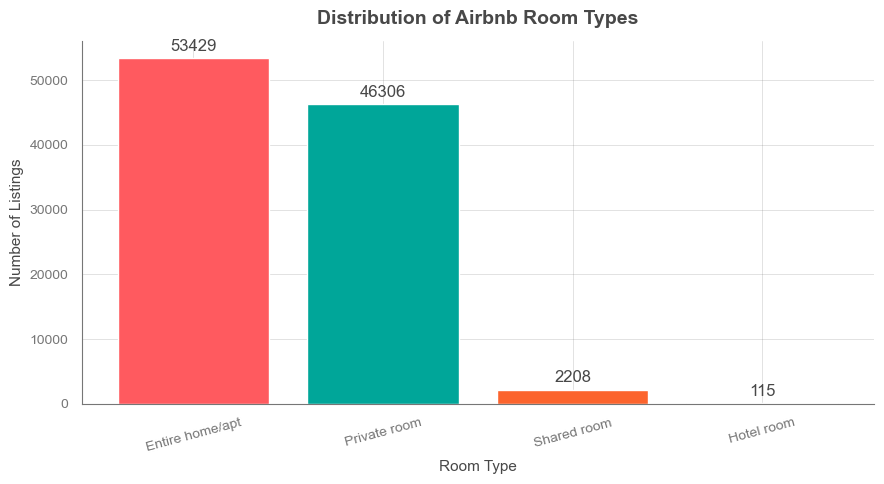

In [116]:
plt.figure(figsize=(9, 5))
room_plot = property_types["listing_count"]
bars = plt.bar(room_plot.index, room_plot.values,
               color=[ROOM_TYPE_COLORS[k] for k in room_plot.index])
plt.bar_label(bars, padding=3)
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")
plt.title("Distribution of Airbnb Room Types")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


The dataset contains four room types:

- Entire home/apt
- Private room
- Shared room
- Hotel room

**Entire home/apt** is the most common category, followed by **Private room**. The exact counts are displayed in the frequency table and bar chart above. Counts are calculated from all deduplicated listings with a recorded room type.


**Which neighbourhood group has the highest number of listings?**



In [117]:
# Which neighbourhood group has the highest number of listings?
hood_group = (
    df["neighbourhood group"].value_counts(dropna=True)
    .rename_axis("neighbourhood_group")
    .to_frame(name="listing_count")
)
display(hood_group)


,listing_count
neighbourhood_group,
Manhattan,43558
Brooklyn,41631
Queens,13197
Bronx,2694
Staten Island,949


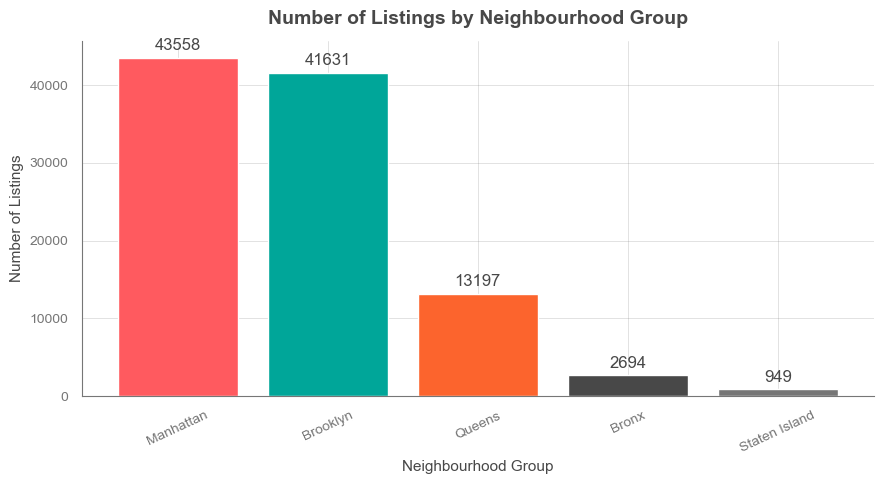

In [118]:
plt.figure(figsize=(9, 5))
bars = plt.bar(hood_group.index, hood_group["listing_count"],
               color=[NEIGHBOURHOOD_COLORS[k] for k in hood_group.index])
plt.bar_label(bars, padding=3)
plt.xlabel("Neighbourhood Group")
plt.ylabel("Number of Listings")
plt.title("Number of Listings by Neighbourhood Group")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


The dataset contains five neighbourhood groups: Manhattan, Brooklyn, Queens, Bronx, and Staten Island. The frequency table and bar chart above show their listing counts. **Manhattan has the highest listing count**, narrowly ahead of Brooklyn. Counts are based on records with a non-missing neighbourhood group.


**Which neighbourhoods group have the highest average prices for Airbnb listings?**

,average_price,listing_count
neighbourhood group,,
Queens,630.217031,13164
Bronx,627.764793,2687
Brooklyn,626.500843,41538
Staten Island,623.990486,946
Manhattan,622.647187,43448


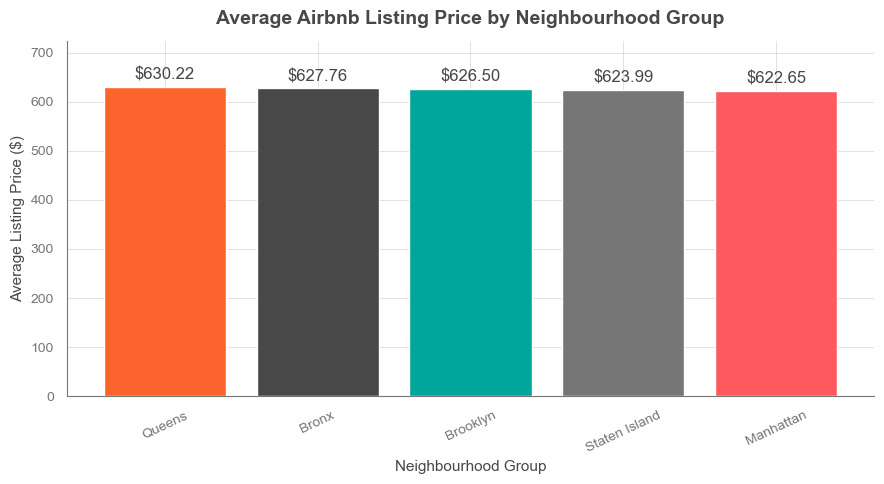

In [119]:
# Average listing price by neighbourhood group, with sample sizes
avg_price = (
    df.dropna(subset=["neighbourhood group", "price_$"])
    .groupby("neighbourhood group")["price_$"]
    .agg(average_price="mean", listing_count="count")
    .sort_values("average_price", ascending=False)
)
display(avg_price)

plt.figure(figsize=(9, 5))
bars = plt.bar(avg_price.index, avg_price["average_price"],
               color=[NEIGHBOURHOOD_COLORS[k] for k in avg_price.index])
plt.bar_label(bars, labels=[f"${v:,.2f}" for v in avg_price["average_price"]], padding=3)
plt.ylim(0, max(avg_price["average_price"]) * 1.15)
plt.xlabel("Neighbourhood Group")
plt.ylabel("Average Listing Price ($)")
plt.title("Average Airbnb Listing Price by Neighbourhood Group")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


The table and chart above compare the mean listing price across neighbourhood groups. **Queens has the highest average price** in this dataset, while Manhattan has the lowest. These are arithmetic means, so unusually high or low listing prices can influence the results. The number of valid price observations in each group should be considered when interpreting the comparison.


**Is there a relationship between the construction year of the property and price?**

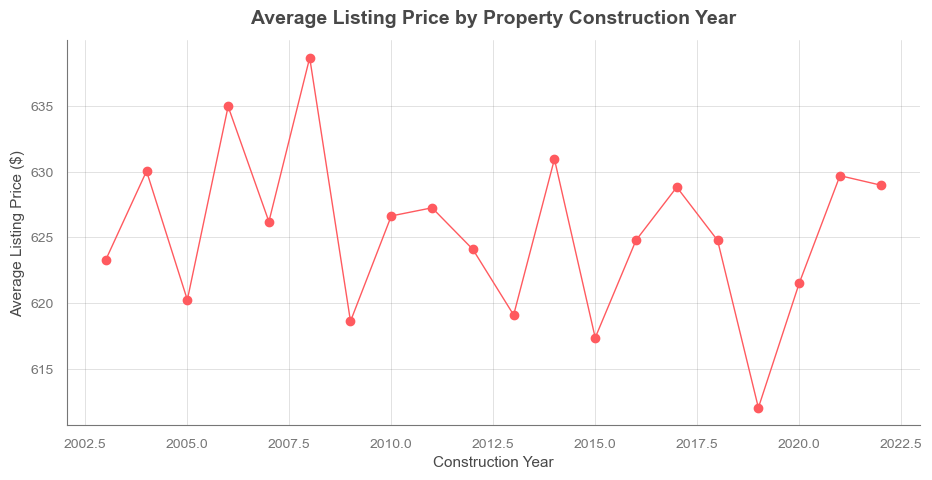

Pearson correlation (construction year vs price): -0.0037
Listings used for correlation: 101,601


In [120]:
# Average price by construction year (only rows with both values present)
construction_data = df.dropna(subset=["Construction year", "price_$"]).copy()
construction_avg = (
    construction_data.groupby("Construction year")["price_$"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(11, 5))
plt.plot(construction_avg.index.astype(int), construction_avg.values, marker="o", linewidth=1,
         color=AIRBNB_CORAL)
plt.xlabel("Construction Year")
plt.ylabel("Average Listing Price ($)")
plt.title("Average Listing Price by Property Construction Year")
plt.grid(alpha=0.25)
plt.show()

construction_corr = construction_data["Construction year"].corr(
    construction_data["price_$"]
)
print(f"Pearson correlation (construction year vs price): {construction_corr:.4f}")
print(f"Listings used for correlation: {len(construction_data):,}")


The line chart shows how average listing price varies by construction year. The pattern fluctuates rather than following a consistent downward trend. The Pearson correlation printed below the chart is approximately zero, indicating **almost no linear relationship** between construction year and price in this dataset. This correlation does not rule out non-linear patterns or other factors influencing price.


**Who are the top 10 hosts by calculated host listing count?**

From the numerous hosts in the dataset, we will see the 10 hosts with the highest calculated host count.

,calculated_host_listings_count,host_ids_in_dataset,listings_in_dataset
host name,,,
Blueground,332.0,312,312
Sonder (NYC),327.0,516,516
Eugene,218.0,80,80
Karen,208.0,435,435
Jeniffer,186.0,267,267
Soya,171.0,65,65
Kaz,161.0,116,116
Hiroki,152.0,118,118
Momoyo,126.0,66,66


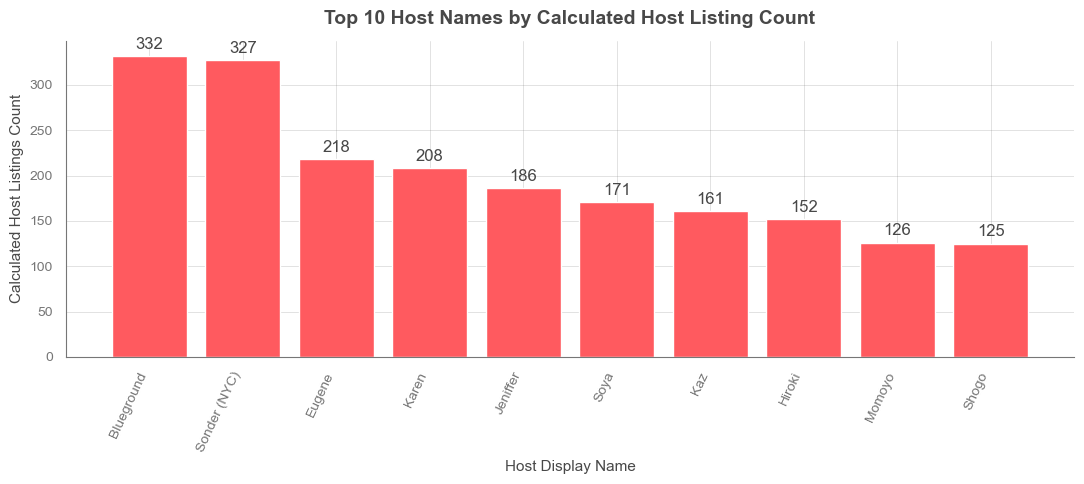

In [121]:
# Rank host display names by their recorded calculated listing count.
# This field is repeated across listings, so use max rather than sum.
# Host names may not be unique; the table also shows distinct host IDs and listings.
host_rows = df.dropna(
    subset=["host name", "calculated host listings count"]
).copy()

hosts = (
    host_rows.groupby("host name")
    .agg(
        calculated_host_listings_count=("calculated host listings count", "max"),
        host_ids_in_dataset=("host id", "nunique"),
        listings_in_dataset=("id", "nunique")
    )
    .sort_values(
        ["calculated_host_listings_count", "listings_in_dataset"],
        ascending=False
    )
    .head(10)
)

display(hosts)

plt.figure(figsize=(11, 5))
bars = plt.bar(hosts.index, hosts["calculated_host_listings_count"], color=AIRBNB_CORAL)
plt.bar_label(bars, padding=3)
plt.xlabel("Host Display Name")
plt.ylabel("Calculated Host Listings Count")
plt.xticks(rotation=65, ha="right")
plt.title("Top 10 Host Names by Calculated Host Listing Count")
plt.tight_layout()
plt.show()


The table and bar chart rank host display names using the `calculated host listings count` field. Since this value is repeated across listing rows, the maximum value per display name is used rather than summing repeated values. The table also reports the number of distinct host IDs and listings associated with each display name in this dataset.

**Limitation:** Host display names are not unique identifiers. A single display name can belong to several different hosts, so each bar shows the highest `calculated host listings count` recorded under that name, not a combined total for everyone using it. Host IDs cannot be used to group listings by host either: in this dataset they are effectively unique to each listing, which is why the host-ID and listing counts in the table are identical. This is therefore a ranking by displayed host name, not a definitive ranking of individual host accounts.


**Are hosts with verified identities more likely to receive positive reviews?**

In [122]:
# Compare mean review rate using rows with both fields available.
review_data = df.dropna(
    subset=["host_identity_verified", "review rate number"]
).copy()

review = (
    review_data.groupby("host_identity_verified")["review rate number"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)
display(review)


,mean,count
host_identity_verified,,
verified,3.285675,50687
unconfirmed,3.272033,50777


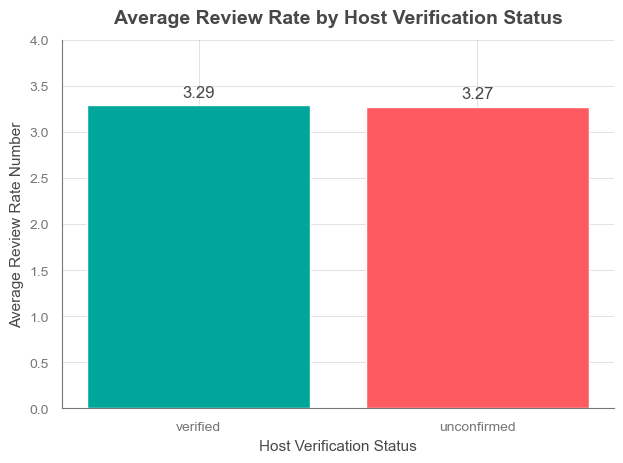

In [123]:
review_plot = review["mean"]
review_bar = plt.bar(review_plot.index, review_plot.values,
                     color=[VERIFICATION_COLORS[k] for k in review_plot.index])
plt.bar_label(review_bar, labels=[f"{v:.2f}" for v in review_plot.values], padding=4)
plt.ylim([0, 4])
plt.xlabel("Host Verification Status")
plt.ylabel("Average Review Rate Number")
plt.title("Average Review Rate by Host Verification Status")
plt.tight_layout()
plt.show()


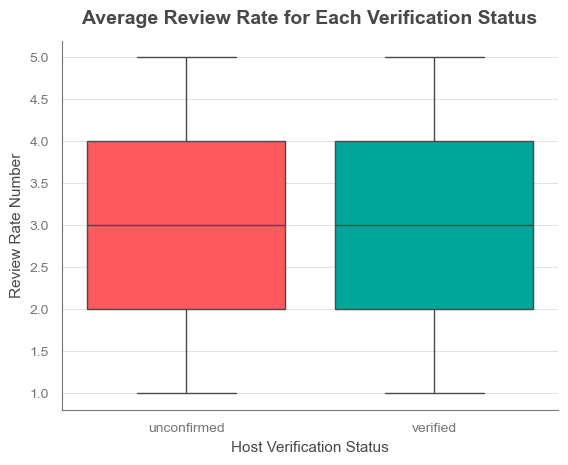

In [124]:
sns.boxplot(data=df, x="host_identity_verified", y="review rate number",
            hue="host_identity_verified", palette=VERIFICATION_COLORS, legend=False,
            saturation=1, linecolor=AIRBNB_DARK);
plt.xlabel('Host Verification Status');
plt.ylabel('Review Rate Number');
plt.title('Average Review Rate for Each Verification Status');

The mean review-rate values for verified and unconfirmed hosts are very close. In this dataset, the verified group has a marginally higher average review rate. The difference is small and descriptive only: it does not establish that identity verification causes better reviews. The sample sizes are shown in the table and should be considered when interpreting the comparison.


**Is there a correlation between the price of a listing and its service fee?**

In [125]:
# Pearson correlation using pairwise complete observations
price_fee_data = df.dropna(subset=["price_$", "service_fee_$"])
price_fee_corr = price_fee_data["price_$"].corr(price_fee_data["service_fee_$"])
print(f"Pearson correlation: {price_fee_corr:.6f}")
print(f"Listings used: {len(price_fee_data):,}")


Pearson correlation: 0.999991
Listings used: 101,572


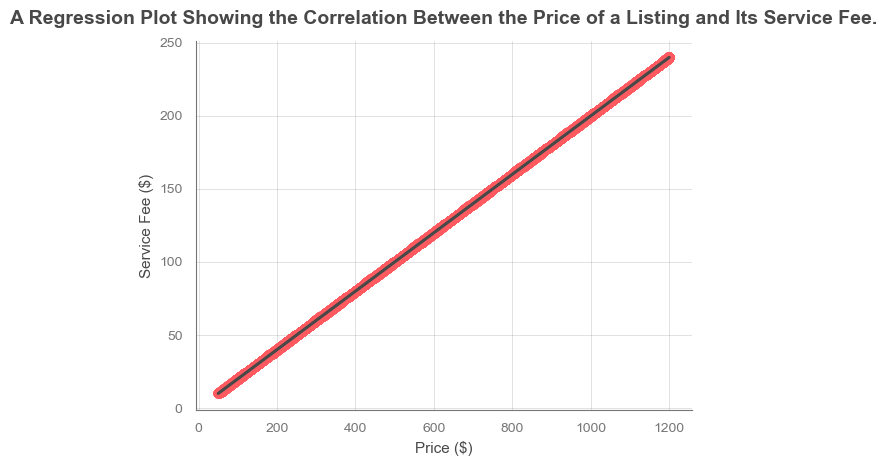

In [126]:
sns.regplot(data=df, x='price_$', y='service_fee_$',
            scatter_kws={'color': AIRBNB_CORAL}, line_kws={'color': AIRBNB_DARK});
plt.xlabel('Price ($)');
plt.ylabel('Service Fee ($)');
plt.title('A Regression Plot Showing the Correlation Between the Price of a Listing and Its Service Fee.');

The Pearson correlation coefficient indicates an **almost perfect positive linear association** between listing price and service fee. The regression plot shows that higher listing prices are associated with higher service fees. This is an association, not evidence that one variable causes the other. The unusually strong relationship may reflect how the service fee is determined or recorded in the source dataset.


**What is the average review rate number (e.g., stars) for listings, and does it vary based on the neighborhood group
and room type?**

In [127]:
# Show both the mean review rate and the number of observations in each group.
ARRN = (
    df.groupby(["neighbourhood group", "room type"])["review rate number"]
    .agg(average_review_rate="mean", listing_count="count")
    .sort_index()
)
display(ARRN)


average_review_rate  listing_count
neighbourhood group room type                                          
Bronx               Entire home/apt             3.346154           1014
                    Private room                3.326873           1548
                    Shared room                 3.260870            115
Brooklyn            Entire home/apt             3.249963          20419
                    Hotel room                  3.857143              7
                    Private room                3.263716          20268
                    Shared room                 3.334957            821
Manhattan           Entire home/apt             3.275869          26248
                    Hotel room                  3.500000            100
                    Private room                3.277431          16177
                    Shared room                 3.254199            893
Queens              Entire home/apt             3.349306           5113
                    Hotel room                  3.750000              8
                    Private room                3.315584           7681
                    Shared room                 3.369748            357
Staten Island       Entire home/apt             3.329087            471
                    Private room                3.477024            457
                    Shared room                 3.533333             15

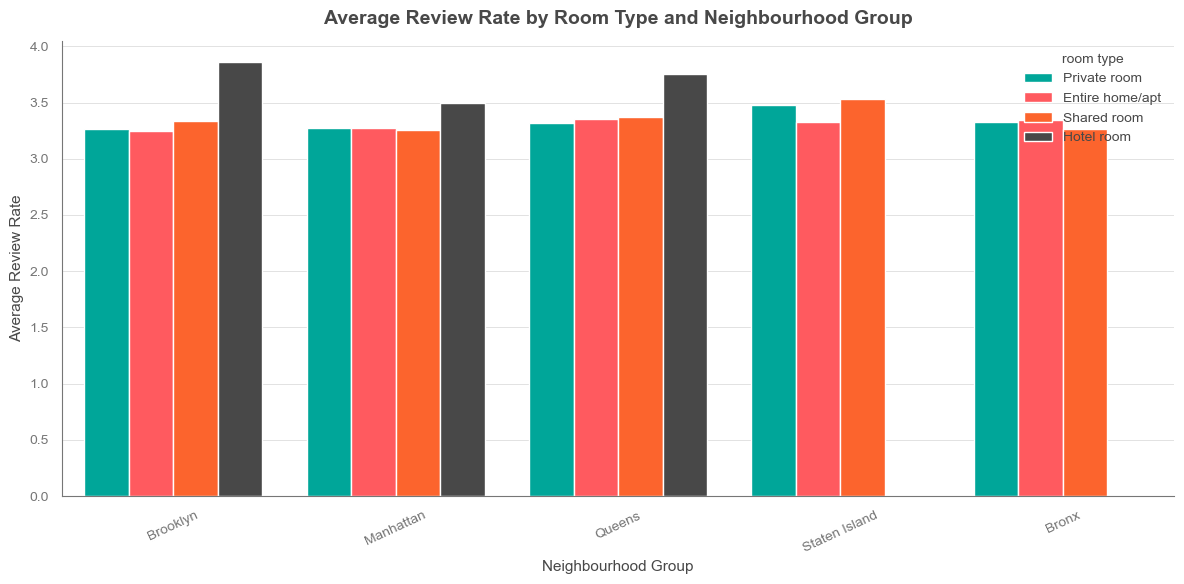

In [128]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df,
    x="neighbourhood group",
    y="review rate number",
    hue="room type",
    errorbar=None,
    palette=ROOM_TYPE_COLORS,
    saturation=1
)
plt.xlabel("Neighbourhood Group")
plt.ylabel("Average Review Rate")
plt.title("Average Review Rate by Room Type and Neighbourhood Group")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


The grouped results show that average review rates vary by both neighbourhood group and room type. Hotel-room listings have the highest average review rate among room types in Brooklyn, Manhattan, and Queens. However, the number of hotel-room observations is small in some groups, so these averages should be interpreted cautiously. The table reports the observation count alongside each average.


**Are hosts with a higher calculated host listings count more likely to maintain higher availability throughout the year?**

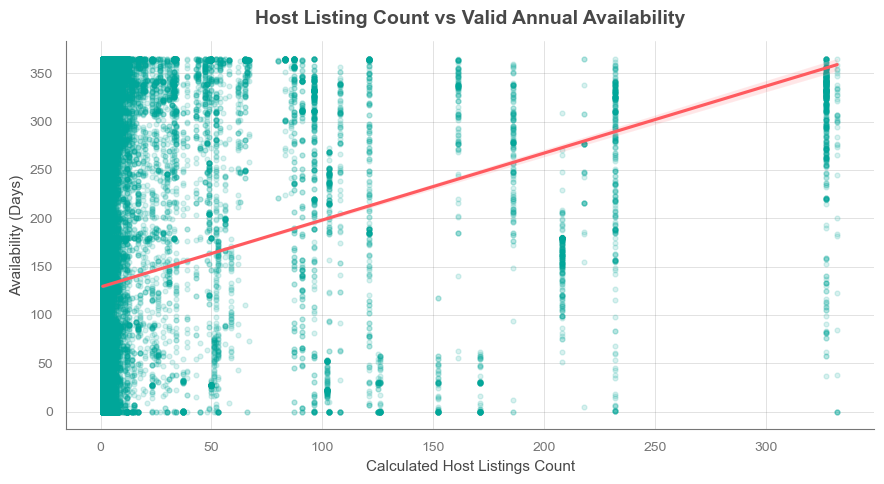

Valid listings used: 98,135


In [129]:
# Availability should be between 0 and 365 days.
availability_data = df.dropna(
    subset=["calculated host listings count", "availability 365"]
).copy()
availability_data = availability_data[
    availability_data["availability 365"].between(0, 365)
]

plt.figure(figsize=(9, 5))
sns.regplot(
    data=availability_data,
    x="calculated host listings count",
    y="availability 365",
    scatter_kws={"alpha": 0.15, "s": 12, "color": AIRBNB_TEAL},
    line_kws={"color": AIRBNB_CORAL}
)
plt.xlabel("Calculated Host Listings Count")
plt.ylabel("Availability (Days)")
plt.title("Host Listing Count vs Valid Annual Availability")
plt.tight_layout()
plt.show()

print(f"Valid listings used: {len(availability_data):,}")


In [130]:
availability_corr = availability_data[
    ["calculated host listings count", "availability 365"]
].corr().iloc[0, 1]
print(f"Pearson correlation: {availability_corr:.5f}")


Pearson correlation: 0.17463


The Pearson correlation coefficient is calculated using only listings with non-missing host listing counts and valid availability values between 0 and 365 days. The result indicates a weak positive linear relationship. Therefore, the data provides only limited evidence that hosts with more calculated listings maintain higher annual availability. Correlation does not imply causation.


# **Conclusion**

This project explored the New York City Airbnb listings dataset through data cleaning, exploratory data analysis, descriptive statistics, and visualizations. The analysis examined room-type distribution, neighbourhood-group listings and prices, construction year, host listing counts, host verification, service fees, review rates, and annual availability.

The main findings are:

- Entire home/apt is the most common room type in the dataset.
- Manhattan has the highest number of listings among the five neighbourhood groups, narrowly ahead of Brooklyn.
- Queens has the highest mean listing price among the neighbourhood groups.
- Construction year has almost no linear correlation with listing price in this dataset.
- The top-host ranking is based on host display names, which are not unique identifiers; host IDs are effectively unique to each listing, so the ranking reflects displayed host names rather than individual host accounts.
- Verified and unconfirmed hosts have very similar average review rates.
- Listing price and service fee have an almost perfect positive correlation.
- Review-rate averages vary by neighbourhood group and room type; small group sizes should be considered.
- Host listing count has only a weak positive relationship with valid annual availability.

The analysis is descriptive and based on the available dataset. It does not establish causal relationships, and missing values or data-quality limitations may affect individual comparisons.

Further work could include investigating pricing drivers with regression models, studying review text through sentiment analysis, and developing predictive models for listing prices or availability. Any predictive model should use a carefully validated dataset and an appropriate train/test evaluation strategy.
